# Praktikum 2 - Klasifikasi Data Iris dengan Keras (TensorFlow)

Notebook ini membangun JST menggunakan **Keras/TensorFlow** untuk mengklasifikasikan
dataset **Iris** ke dalam 3 kelas.

**Tugas:**
- **Tugas 2:** Mengubah jumlah neuron hidden layer dan membandingkan akurasinya dengan konfigurasi awal.
- **Tugas 3:** Membandingkan aktivasi **Sigmoid** vs **ReLU** pada dataset Iris (loss dan akurasi).

## Langkah 1 - Import Library

In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'  # kurangi log TensorFlow

import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
import tensorflow as tf

%matplotlib inline
RANDOM_STATE = 42
SEEDS = [42, 7, 123]  # untuk pengujian berulang

print('TensorFlow:', tf.__version__)
print('Keras     :', tf.keras.__version__)

TensorFlow: 2.20.0
Keras     : 3.10.0


## Langkah 2 - Load Dataset Iris

In [2]:
# Load dataset
iris = load_iris()
X = iris.data
y = iris.target.reshape(-1, 1)

# One-hot encoding (sparse_output=False untuk scikit-learn versi baru)
encoder = OneHotEncoder(sparse_output=False)
y = encoder.fit_transform(y)

# Split data 80:20 (stratified agar proporsi kelas seimbang)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y.argmax(axis=1)
)

print('Total data :', X.shape)
print('Data latih :', X_train.shape)
print('Data uji   :', X_test.shape)
print('Kelas      :', list(iris.target_names))
print('Distribusi y_train:', np.bincount(y_train.argmax(axis=1)))

Total data : (150, 4)
Data latih : (120, 4)
Data uji   : (30, 4)
Kelas      : [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]
Distribusi y_train: [40 40 40]


## Langkah 3 - Fungsi Pembangun Model

Agar perbandingan adil, semua eksperimen menggunakan split data, epoch, batch size,
optimizer, dan loss yang sama. Seed diatur pada setiap model agar hasil reproducible.
Output layer selalu menggunakan **softmax** (3 kelas).

In [3]:
def build_model(hidden_units=(10, 8), activation='relu', seed=RANDOM_STATE):
    tf.keras.utils.set_random_seed(seed)

    layers = [tf.keras.Input(shape=(X.shape[1],))]
    for units in hidden_units:
        layers.append(tf.keras.layers.Dense(units, activation=activation))
    layers.append(tf.keras.layers.Dense(y.shape[1], activation='softmax'))

    model = tf.keras.Sequential(layers)
    model.compile(
        optimizer='adam',
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    return model


def train_evaluate(hidden_units=(10, 8), activation='relu', seed=RANDOM_STATE,
                   epochs=50, batch_size=8, verbose=0):
    model = build_model(hidden_units, activation, seed)

    history = model.fit(
        X_train, y_train,
        epochs=epochs,
        batch_size=batch_size,
        verbose=verbose
    )

    train_loss, train_acc = model.evaluate(X_train, y_train, verbose=0)
    test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)

    return model, history, {
        'Train Loss': train_loss,
        'Train Accuracy': train_acc,
        'Test Loss': test_loss,
        'Test Accuracy': test_acc,
    }

## Langkah 4 - Konfigurasi Awal (10 - 8, ReLU)

Konfigurasi awal sesuai modul: Dense(10, ReLU) -> Dense(8, ReLU) -> Dense(3, Softmax),
dilatih selama 50 epoch dengan batch size 8.

In [4]:
model_awal, history_awal, metrics_awal = train_evaluate(
    hidden_units=(10, 8), activation='relu', seed=RANDOM_STATE, epochs=50, batch_size=8
)

model_awal.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 10)             │            50 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │            88 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 497 (1.95 KB)

 Trainable params: 165 (660.00 B)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 332 (1.30 KB)

In [5]:
loss, acc = model_awal.evaluate(X_test, y_test, verbose=0)

print(f'Loss data uji    : {loss:.4f}')
print(f'Akurasi data uji : {acc:.4f} ({acc * 100:.2f}%)')

for key, value in metrics_awal.items():
    print(f'{key:<16}: {value:.4f}')

Loss data uji    : 0.2216
Akurasi data uji : 1.0000 (100.00%)
Train Loss      : 0.2135
Train Accuracy  : 0.9667
Test Loss       : 0.2216
Test Accuracy   : 1.0000


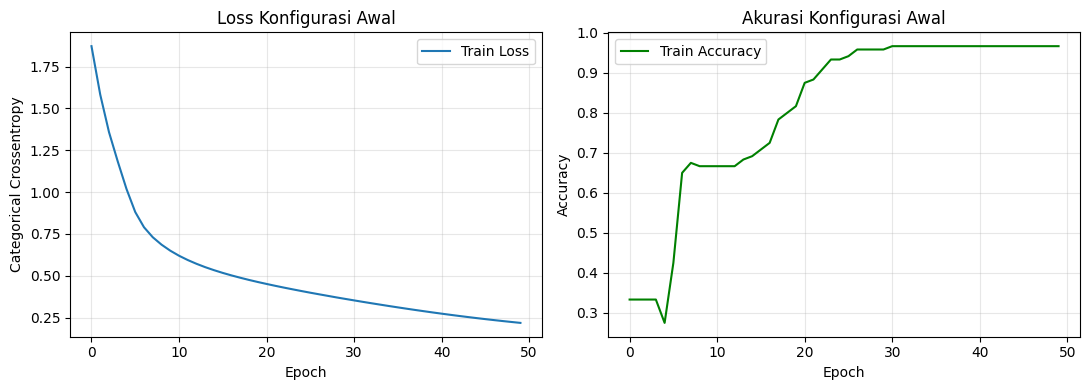

In [6]:
# Kurva pembelajaran konfigurasi awal
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(history_awal.history['loss'], label='Train Loss')
axes[0].set_title('Loss Konfigurasi Awal')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Categorical Crossentropy')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(history_awal.history['accuracy'], label='Train Accuracy', color='green')
axes[1].set_title('Akurasi Konfigurasi Awal')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Tugas 2 - Perubahan Jumlah Neuron Hidden Layer

Beberapa konfigurasi hidden layer diuji dengan arsitektur 2 layer tersembunyi:

| Nama | Hidden Layer |
|------|--------------|
| Kecil  | 4 - 4 |
| Awal   | 10 - 8 (konfigurasi awal) |
| Sedang | 20 - 16 |
| Besar  | 32 - 32 |

Setiap konfigurasi dilatih dengan **3 seed berbeda** untuk melihat rata-rata dan variasi performa.

In [7]:
configs = [
    ('Kecil (4-4)', (4, 4)),
    ('Awal (10-8)', (10, 8)),
    ('Sedang (20-16)', (20, 16)),
    ('Besar (32-32)', (32, 32)),
]

rows_t2 = []

for name, units in configs:
    for seed in SEEDS:
        _, _, m = train_evaluate(
            hidden_units=units, activation='relu', seed=seed,
            epochs=50, batch_size=8
        )
        rows_t2.append({
            'Konfigurasi': name,
            'Seed': seed,
            'Train Accuracy': m['Train Accuracy'],
            'Test Accuracy': m['Test Accuracy'],
            'Test Loss': m['Test Loss'],
        })

df_t2 = pd.DataFrame(rows_t2)
df_t2

,Konfigurasi,Seed,Train Accuracy,Test Accuracy,Test Loss
0,Kecil (4-4),42,0.658333,0.666667,0.759134
1,Kecil (4-4),7,0.666667,0.666667,0.763444
2,Kecil (4-4),123,0.741667,0.633333,0.633565
3,Awal (10-8),42,0.966667,1.000000,0.221645
4,Awal (10-8),7,0.983333,0.966667,0.226737
5,Awal (10-8),123,0.975000,1.000000,0.155124
6,Sedang (20-16),42,0.975000,1.000000,0.147028
7,Sedang (20-16),7,0.975000,0.933333,0.159072
8,Sedang (20-16),123,0.950000,1.000000,0.116528
9,Besar (32-32),42,0.983333,0.966667,0.117418


In [8]:
order_t2 = [name for name, _ in configs]

summary_rows = []
for name in order_t2:
    sub = df_t2[df_t2['Konfigurasi'] == name]
    summary_rows.append({
        'Konfigurasi': name,
        'Train Accuracy': f"{sub['Train Accuracy'].mean():.4f} ± {sub['Train Accuracy'].std():.4f}",
        'Test Accuracy': f"{sub['Test Accuracy'].mean():.4f} ± {sub['Test Accuracy'].std():.4f}",
        'Test Loss': f"{sub['Test Loss'].mean():.4f} ± {sub['Test Loss'].std():.4f}",
    })

summary_t2 = pd.DataFrame(summary_rows)
summary_t2

,Konfigurasi,Train Accuracy,Test Accuracy,Test Loss
0,Kecil (4-4),0.6889 ± 0.0459,0.6556 ± 0.0192,0.7187 ± 0.0738
1,Awal (10-8),0.9750 ± 0.0083,0.9889 ± 0.0192,0.2012 ± 0.0400
2,Sedang (20-16),0.9667 ± 0.0144,0.9778 ± 0.0385,0.1409 ± 0.0219
3,Besar (32-32),0.9778 ± 0.0048,0.9667 ± 0.0333,0.1080 ± 0.0128


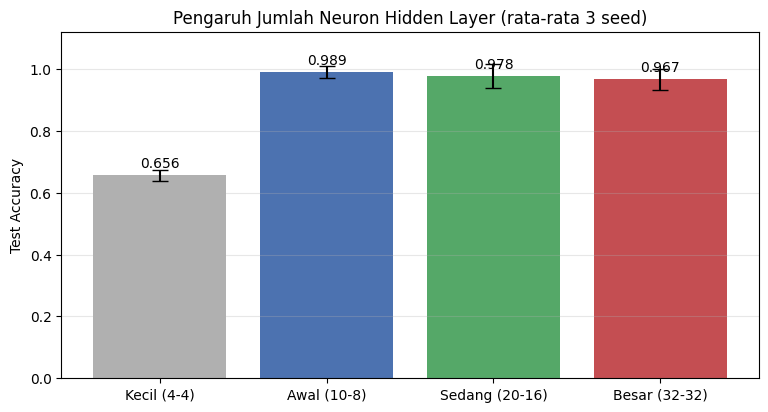

In [9]:
# Grafik rata-rata akurasi data uji
means = df_t2.groupby('Konfigurasi')['Test Accuracy'].mean().reindex(order_t2)
stds = df_t2.groupby('Konfigurasi')['Test Accuracy'].std().reindex(order_t2)

plt.figure(figsize=(9, 4.5))
bars = plt.bar(means.index, means.values, yerr=stds.values, capsize=6,
               color=['#b0b0b0', '#4c72b0', '#55a868', '#c44e52'])

for bar, value in zip(bars, means.values):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.015,
             f'{value:.3f}', ha='center', va='bottom')

plt.ylim(0, 1.12)
plt.ylabel('Test Accuracy')
plt.title('Pengaruh Jumlah Neuron Hidden Layer (rata-rata 3 seed)')
plt.grid(axis='y', alpha=0.3)
plt.show()

## Tugas 3 - Sigmoid vs ReLU

Arsitektur yang dibandingkan sama, yaitu **10 - 8 -> 3**, dengan 50 epoch dan batch size 8.
Hanya fungsi aktivasi pada hidden layer yang diubah. Setiap aktivasi dijalankan pada 3 seed.

In [10]:
activations = ['relu', 'sigmoid']

rows_t3 = []
histories_t3 = {act: [] for act in activations}

for act in activations:
    for seed in SEEDS:
        _, history, m = train_evaluate(
            hidden_units=(10, 8), activation=act, seed=seed,
            epochs=50, batch_size=8
        )
        rows_t3.append({
            'Aktivasi': act,
            'Seed': seed,
            'Train Loss': m['Train Loss'],
            'Train Accuracy': m['Train Accuracy'],
            'Test Loss': m['Test Loss'],
            'Test Accuracy': m['Test Accuracy'],
        })
        histories_t3[act].append(history.history)

df_t3 = pd.DataFrame(rows_t3)
df_t3

,Aktivasi,Seed,Train Loss,Train Accuracy,Test Loss,Test Accuracy
0,relu,42,0.213525,0.966667,0.221645,1.000000
1,relu,7,0.215231,0.983333,0.226737,0.966667
2,relu,123,0.152891,0.975000,0.155124,1.000000
3,sigmoid,42,0.576738,0.775000,0.575750,0.766667
4,sigmoid,7,0.596724,0.891667,0.594738,0.833333
5,sigmoid,123,0.557071,0.850000,0.555897,0.833333


In [11]:
summary_rows_t3 = []
for act in activations:
    sub = df_t3[df_t3['Aktivasi'] == act]
    summary_rows_t3.append({
        'Aktivasi': act,
        'Train Loss': f"{sub['Train Loss'].mean():.4f} ± {sub['Train Loss'].std():.4f}",
        'Train Accuracy': f"{sub['Train Accuracy'].mean():.4f} ± {sub['Train Accuracy'].std():.4f}",
        'Test Loss': f"{sub['Test Loss'].mean():.4f} ± {sub['Test Loss'].std():.4f}",
        'Test Accuracy': f"{sub['Test Accuracy'].mean():.4f} ± {sub['Test Accuracy'].std():.4f}",
    })

summary_t3 = pd.DataFrame(summary_rows_t3)
summary_t3

,Aktivasi,Train Loss,Train Accuracy,Test Loss,Test Accuracy
0,relu,0.1939 ± 0.0355,0.9750 ± 0.0083,0.2012 ± 0.0400,0.9889 ± 0.0192
1,sigmoid,0.5768 ± 0.0198,0.8389 ± 0.0591,0.5755 ± 0.0194,0.8111 ± 0.0385


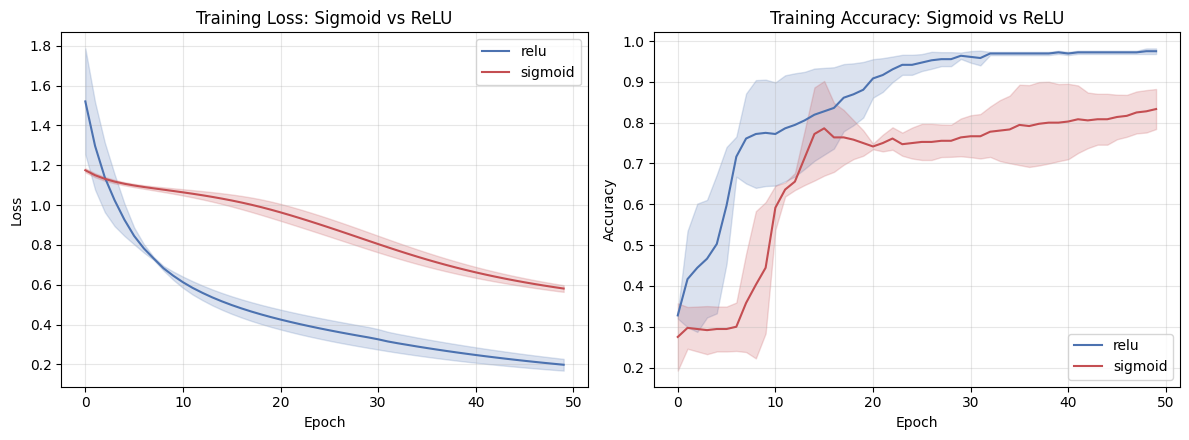

In [12]:
# Bandingkan kurva loss dan akurasi (rata-rata +- std dari 3 seed)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for act, color in zip(activations, ['#4c72b0', '#c44e52']):
    loss_hist = np.array([h['loss'] for h in histories_t3[act]])
    acc_hist = np.array([h['accuracy'] for h in histories_t3[act]])
    epoch_axis = np.arange(loss_hist.shape[1])

    loss_mean, loss_std = loss_hist.mean(axis=0), loss_hist.std(axis=0)
    acc_mean, acc_std = acc_hist.mean(axis=0), acc_hist.std(axis=0)

    axes[0].plot(epoch_axis, loss_mean, label=act, color=color)
    axes[0].fill_between(epoch_axis, loss_mean - loss_std, loss_mean + loss_std,
                         alpha=0.2, color=color)

    axes[1].plot(epoch_axis, acc_mean, label=act, color=color)
    axes[1].fill_between(epoch_axis, acc_mean - acc_std, acc_mean + acc_std,
                         alpha=0.2, color=color)

axes[0].set_title('Training Loss: Sigmoid vs ReLU')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].set_title('Training Accuracy: Sigmoid vs ReLU')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Analisis

**Tugas 2 - Jumlah neuron hidden layer:**
- Konfigurasi terlalu kecil (4-4) mengalami *underfitting*: akurasi uji rendah dan loss tinggi.
- Konfigurasi awal (10-8) sudah mampu mencapai akurasi tinggi pada data Iris.
- Menambah neuron (20-16 dan 32-32) tidak selalu meningkatkan akurasi secara signifikan;
  dataset Iris hanya memiliki 4 fitur dan 150 data, sehingga kapasitas tambahan cepat
  mengalami *diminishing return* dan berpotensi overfitting.
- Dengan demikian, ukuran hidden layer perlu disesuaikan dengan kompleksitas data.

**Tugas 3 - Sigmoid vs ReLU:**
- ReLU umumnya menghasilkan **loss lebih rendah** dan **akurasi lebih tinggi** pada jumlah
  epoch yang sama, karena gradiennya tidak mengecil di rentang positif sehingga konvergensi
  lebih cepat.
- Sigmoid cenderung lebih lambat konvergen dan dapat mengalami *vanishing gradient*,
  terutama pada nilai ekstrem.
- Untuk dataset kecil dan sederhana seperti Iris, perbedaan keduanya bisa mengecil jika
  jumlah epoch diperbesar atau arsitektur dibuat lebih besar.

**Catatan:** Nilai dapat sedikit berbeda jika seed diubah. Karena itu setiap konfigurasi
diuji dengan 3 seed dan dilaporkan dalam bentuk rata-rata ± standar deviasi.

## Kesimpulan

In [13]:
print('=== Tugas 2: Variasi Hidden Layer (ReLU) ===')
print(summary_t2.to_string(index=False))

print('\n=== Tugas 3: Sigmoid vs ReLU ===')
print(summary_t3.to_string(index=False))

=== Tugas 2: Variasi Hidden Layer (ReLU) ===
   Konfigurasi  Train Accuracy   Test Accuracy       Test Loss
   Kecil (4-4) 0.6889 ± 0.0459 0.6556 ± 0.0192 0.7187 ± 0.0738
   Awal (10-8) 0.9750 ± 0.0083 0.9889 ± 0.0192 0.2012 ± 0.0400
Sedang (20-16) 0.9667 ± 0.0144 0.9778 ± 0.0385 0.1409 ± 0.0219
 Besar (32-32) 0.9778 ± 0.0048 0.9667 ± 0.0333 0.1080 ± 0.0128

=== Tugas 3: Sigmoid vs ReLU ===
Aktivasi      Train Loss  Train Accuracy       Test Loss   Test Accuracy
    relu 0.1939 ± 0.0355 0.9750 ± 0.0083 0.2012 ± 0.0400 0.9889 ± 0.0192
 sigmoid 0.5768 ± 0.0198 0.8389 ± 0.0591 0.5755 ± 0.0194 0.8111 ± 0.0385
